# LightGBM

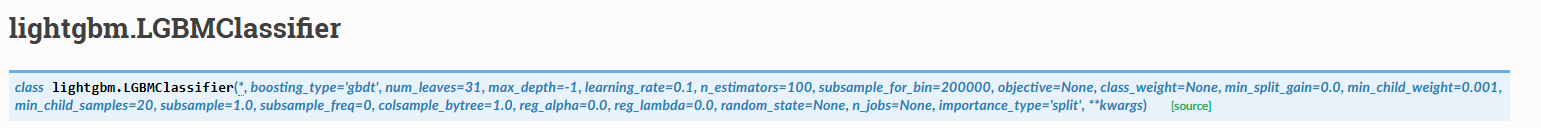

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import AdaBoostClassifier,GradientBoostingClassifier
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import make_column_selector, make_column_transformer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import StandardScaler, MaxAbsScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from tqdm import tqdm
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier, LGBMRegressor

In [3]:
df = pd.read_csv("../Day5/HR_comma_sep.csv")

In [4]:
X,y = df.drop("left",axis=1), df["left"]
X_train, X_test, y_train, y_test = train_test_split(X,y,random_state=26,test_size=0.3,stratify=y)

In [5]:
ohc = OneHotEncoder(sparse_output=False, drop="first").set_output(transform="pandas")
ct = make_column_transformer((ohc,make_column_selector(dtype_include=object)),
                             ("passthrough", make_column_selector(dtype_include=['int64','float64'])),
                             verbose_feature_names_out=False)
ct = ct.set_output(transform='pandas')

In [8]:
lr = np.linspace(0.01,0.9,10)
max_depth = [None, 2, 3, 4]
n_estimators = [25, 50, 100]
scores = []
for l in tqdm(lr):
    for m in max_depth:
        for n in n_estimators:
            gdc = LGBMClassifier(random_state=26,verbose = -1,learning_rate=l, n_estimators= n, max_depth= m)
            pipe = Pipeline([("CT",ct),("GDC",gdc)])
            pipe.fit(X_train,y_train)
            y_pred = pipe.predict(X_test)
            scores.append([l,m,n,accuracy_score(y_test, y_pred)])
df_scores = pd.DataFrame(scores, columns=["Learning Rate","Max Depth", "N", "Score"])
df_scores.sort_values("Score",ascending=False)

100%|██████████████████████████████████████████████████████████████████████████████████| 10/10 [00:11<00:00,  1.12s/it]


,Learning Rate,Max Depth,N,Score
37,0.306667,NaN,50,0.988664
26,0.207778,NaN,100,0.988664
50,0.405556,NaN,100,0.988442
61,0.504444,NaN,50,0.988442
38,0.306667,NaN,100,0.988442
...,...,...,...,...
4,0.010000,2.0,50,0.762392
9,0.010000,4.0,25,0.762169
6,0.010000,3.0,25,0.762169
3,0.010000,2.0,25,0.762169
